In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
import pandas as pd
from sklearn.utils import resample
import tensorflow as tf


In [2]:
# Download the dataset from Hugging Face.
# (This caches it locally so it only downloads once)
dataset = load_dataset("birdsql/bird_sql_dev_20251106")

# First available split and convert it to a Pandas DataFrame.
split_name = list(dataset.keys())[0]
df = dataset[split_name].to_pandas()

# View the first 5 rows of the dataset.
display(df.head())

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

dev_20251106-00000-of-00001.json:   0%|          | 0.00/947k [00:00<?, ?B/s]

Generating dev_20251106 split:   0%|          | 0/1534 [00:00<?, ? examples/s]

,question_id,db_id,question,evidence,SQL,difficulty
0,0,california_schools,For the school with the highest free meal rate...,Free meal rate = Free Meal Count (K-12) / Enro...,WITH CountyStats AS (\n SELECT \n f....,challenging
1,1,california_schools,Please list the lowest three eligible free rat...,Eligible free rates for students aged 5-17 = `...,SELECT `Free Meal Count (Ages 5-17)` / `Enroll...,moderate
2,2,california_schools,For charter schools in Fresno County Office of...,Charter schools refers to `Charter School (Y/N...,WITH CharterSchoolInfo AS (\n SELECT \n ...,challenging
3,3,california_schools,For the non-charter school with more than 100 ...,Non-charter schools have Charter School (Y/N) ...,WITH SchoolRanking AS (\n SELECT \n ...,challenging
4,4,california_schools,Please list the phone numbers of the direct ch...,Charter schools refers to `Charter School (Y/N...,SELECT T2.Phone FROM frpm AS T1 INNER JOIN sch...,moderate


In [3]:
# Check for na values across all columns not counting empty spaces
print(df.isna().sum())

question_id    0
db_id          0
question       0
evidence       0
SQL            0
difficulty     0
dtype: int64


difficulty
simple         860
moderate       443
challenging    231
Name: count, dtype: int64


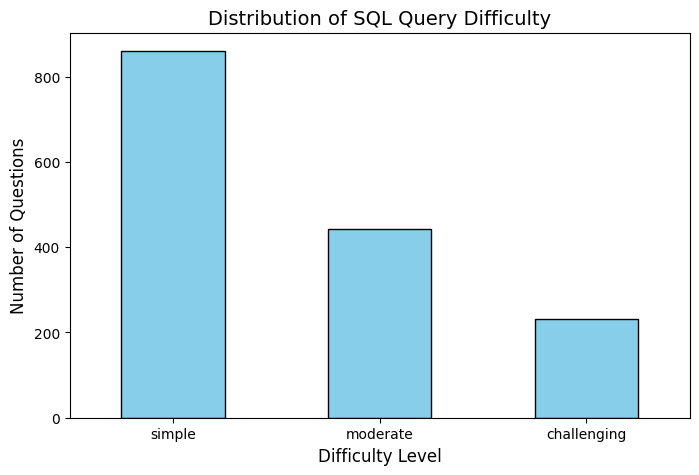

In [4]:
# See the exact numbers before plotting
print(df['difficulty'].value_counts())

# Count the occurrences of each difficulty level and plot them
difficulty_counts = df['difficulty'].value_counts()

# Create the bar chart
difficulty_counts.plot(kind='bar', figsize=(8, 5), color='skyblue', edgecolor='black')

# Add titles and labels
plt.title('Distribution of SQL Query Difficulty', fontsize=14)
plt.xlabel('Difficulty Level', fontsize=12)
plt.ylabel('Number of Questions', fontsize=12)

# Keep the text labels on the bottom horizontal so they are easy to read
plt.xticks(rotation=0)

# Display the chart
plt.show()

### 📊 Query Difficulty Distribution Analysis

This bar chart visualizes the distribution of SQL query difficulty within the dataset, categorized into simple, moderate, and challenging levels. The data exhibits a clear right-skew, indicating an imbalance toward easier queries.   

- **Simple:** The majority class, containing over 800 questions.   
- **Moderate:** The middle tier, containing approximately 440 questions.   
- **Challenging:** The minority class, containing roughly 230 questions.   

> **💡 EDA Takeaway**
> The dataset is heavily imbalanced, with simple queries outnumbering challenging ones by nearly four to one. For training a Data Analyst AI Agent, this means the model will have ample examples of basic SQL syntax but may lack sufficient examples to learn complex joins, window functions, or subqueries. To prevent the model from biasing toward simple queries, will likely need to upsample the "challenging" and "moderate" subsets or apply class weights during the fine-tuning phase of project.

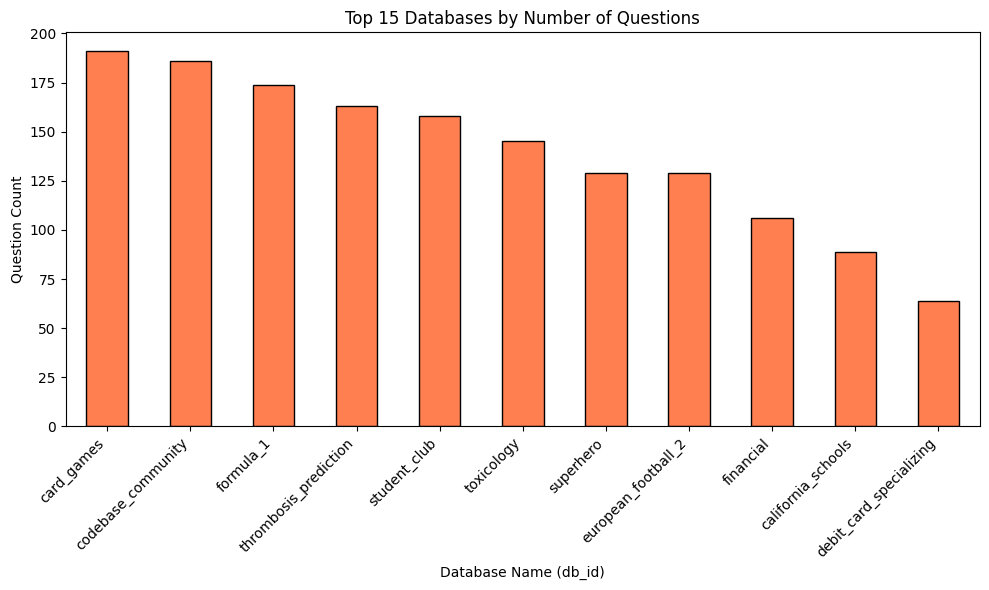

In [5]:

top_dbs = df['db_id'].value_counts()

plt.figure(figsize=(10, 6))
top_dbs.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Top 15 Databases by Number of Questions')
plt.xlabel('Database Name (db_id)')
plt.ylabel('Question Count')
plt.xticks(rotation=45, ha='right') # Slant the text so database names fit
plt.tight_layout()
plt.show()

### 📊 Domain Distribution Analysis

This bar chart visualizes the distribution of questions across the most frequently used databases in the dataset. The data exhibits a gradual decline across a wide variety of topics rather than a sharp drop-off.

- **Top Tier:** The `card_games` and `codebase_community` databases lead the dataset, each containing just under 200 questions.
- **Middle Tier:** Domains like `formula_1`, `thrombosis_prediction`, and `student_club` follow closely, ranging roughly between 150 and 175 questions.
- **Lower Tier (of the top group):** The counts steadily decrease down to `california_schools` (approx. 100 questions) and `debit_card_specializing` (approx. 65 questions).

> **💡 EDA Takeaway**
> The dataset features a highly diverse set of domains—ranging from sports (`formula_1`) and healthcare (`toxicology`) to finance (`financial`) and gaming (`card_games`). For training the Data Analyst AI Agent project, this rich variety is a massive advantage. It ensures the model will learn to generalize its text-to-SQL translation skills across different industries and vocabulary, rather than overfitting to the schema of a single corporate database. Because even the most frequent database caps out at under 200 questions, the model will be forced to rely on logical reasoning to succeed.

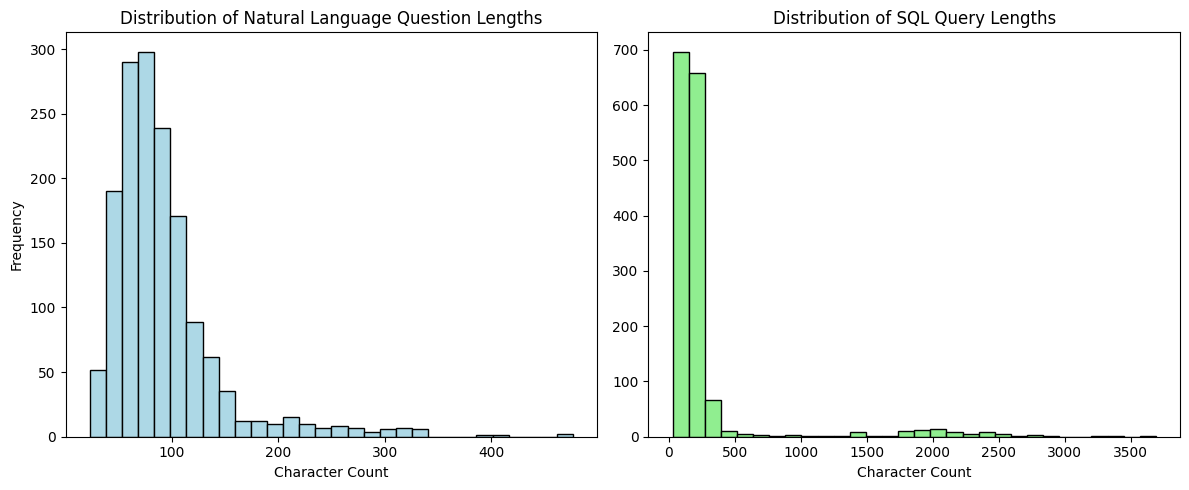

In [6]:
# Create new columns that count the number of characters in the questions and SQL
df['question_length'] = df['question'].astype(str).apply(len)
df['sql_length'] = df['SQL'].astype(str).apply(len)

plt.figure(figsize=(12, 5))

# Plot 1: Question Lengths
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
plt.hist(df['question_length'], bins=30, color='lightblue', edgecolor='black')
plt.title('Distribution of Natural Language Question Lengths')
plt.xlabel('Character Count')
plt.ylabel('Frequency')

# Plot 2: SQL Lengths
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
plt.hist(df['sql_length'], bins=30, color='lightgreen', edgecolor='black')
plt.title('Distribution of SQL Query Lengths')
plt.xlabel('Character Count')

plt.tight_layout()
plt.show()

### 📊 Text Length Distributions (Questions vs. SQL)

These histograms compare the character length distributions for the natural language questions (left) and their corresponding SQL queries (right). Both distributions exhibit a distinct right-skew, though the scales differ significantly.

- **Natural Language Questions:** The majority of user questions are highly concise, with frequencies peaking sharply between 50 and 100 characters. The distribution tapers off steadily, with very few questions exceeding the 300-character mark.
- **SQL Queries:** The SQL character counts are heavily concentrated under 500 characters. However, unlike the questions, the SQL distribution features an extreme long tail that extends well past 3,500 characters, indicating the presence of highly complex, multi-layered queries.

> **💡 EDA Takeaway**
> The token length requirements for the model's inputs and outputs are highly asymmetrical. While the input prompts (the natural language questions) are predictably short, the target outputs (the SQL queries) can occasionally be massive. When configuring the maximum token limits for fine-tuning or API prompting for a Data Analyst AI Agent, it must ensure the model's output generation limit (e.g., `max_tokens`) is set high enough to accommodate those rare 3,000+ character SQL queries. If the model truncate these long sequences during training or inference, the app will fail whenever an user asks a question that requires a complex, multi-table `JOIN` or nested subquery.

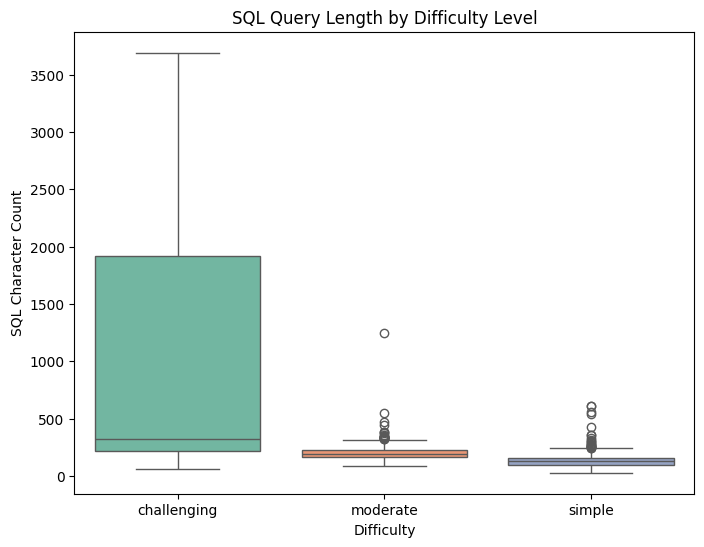

In [7]:
plt.figure(figsize=(8, 6))

sns.boxplot(data=df, x='difficulty', y='sql_length', palette='Set2', hue='difficulty',legend=False)

plt.title('SQL Query Length by Difficulty Level')
plt.xlabel('Difficulty')
plt.ylabel('SQL Character Count')
plt.show()

### 📊 SQL Complexity vs. Difficulty Analysis

This box plot visualizes the relationship between the categorized difficulty level of a query and its actual character length. The data reveals that as difficulty increases, the variance in query length expands dramatically.

- **Challenging:** Exhibits massive variance. While the median length is relatively low (roughly 300–400 characters), the interquartile range is extremely broad, and the upper whisker extends beyond 3,500 characters.
- **Moderate:** Shows a highly concentrated distribution with a median near 200 characters. It features a compact interquartile range but includes several outliers extending up to approximately 1,250 characters.
- **Simple:** The tightest distribution, with nearly all queries falling under 200 characters and a few outliers capping around 600 characters.

> **💡 EDA Takeaway**
> The "challenging" category is defined by extreme variance rather than just a high median length. This indicates that a complex query is not always long—it might just require advanced, concise syntax like a specific window function or complex join condition. However, every exceptionally long query in the dataset is classified as challenging. For the Data Analyst AI Agent, this means the model must be trained to understand complex logical reasoning and database schemas, as it cannot rely on simply generating more tokens to solve harder problems.

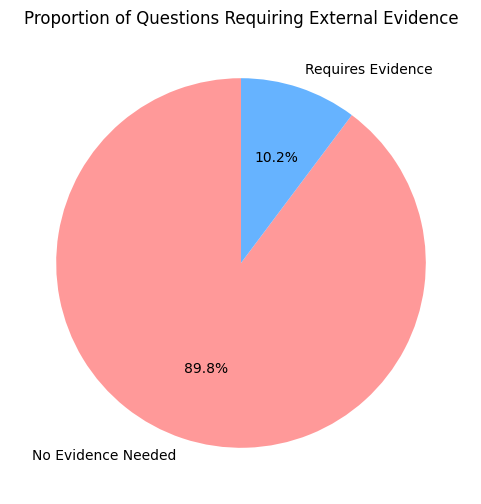

In [8]:
# We count it as "Has Evidence" if the string length is greater than 2
df['has_evidence'] = df['evidence'].astype(str).str.strip().apply(lambda x: len(x) > 2)

evidence_counts = df['has_evidence'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(evidence_counts,
        labels=['No Evidence Needed', 'Requires Evidence'],
        autopct='%1.1f%%', # Shows the percentages on the chart
        colors=['#ff9999','#66b3ff'],
        startangle=90)

plt.title('Proportion of Questions Requiring External Evidence')
plt.show()

### 📊 Evidence Availability Analysis

This pie chart visualizes the proportion of questions in the dataset that require external business logic or hints to successfully write the correct SQL query. The data reveals a massive imbalance between queries that are self-contained versus those that need extra context.

- **No Evidence Needed:** The overwhelming majority, making up 89.8% of the dataset.
- **Requires Evidence:** A small minority, accounting for just 10.2% of the questions.

> **💡 EDA Takeaway**
> Because nearly 90% of the training data can be solved using only the user's question and the database schema, a machine learning model might develop a "lazy" heuristic and learn to ignore the `evidence` column entirely. In real-world corporate environments, data analysts rely heavily on external business logic (such as knowing how "net profit" is uniquely calculated for their specific company). To build a truly  Data Analyst AI Agent project, it  must be ensure the model learns to utilize this external knowledge. It may  be needed to oversample this 10.2% minority class during training, or purposefully design the prompt architecture to explicitly force the LLM to read and apply the evidence text before it attempts to write the SQL.

# Data Cleaning



In [9]:
# Returns the total count of empty strings, whitespace, and NaN values for question column
((df['question'].isna()) | (df['question'].astype(str).str.strip() == '')).sum()


np.int64(0)

In [10]:
# Returns the total count of empty strings, whitespace, and NaN values for evidence column
((df['evidence'].isna()) | (df['evidence'].astype(str).str.strip() == '')).sum()


np.int64(157)

In [11]:
# Returns the total count of empty strings, whitespace, and NaN values for SQL column
((df['SQL'].isna()) | (df['SQL'].astype(str).str.strip() == '')).sum()


np.int64(0)

In [12]:
# Create a copy of the dataframe for preprocessing
df_clean = df.copy()

# Fill missing values in the 'evidence' column with an empty string
df_clean['evidence'] = df_clean['evidence'].fillna("")

print(f"Total rows after cleaning: {len(df_clean)}")

Total rows after cleaning: 1534


# Addressing the EDA Imbalances (Upsampling)

EDA showed that "simple" queries and "no evidence" queries heavily dominate the dataset. If the model is train as-is, it will perform poorly on complex tasks. Duplicating (upsample) the challenging queries to force the model to pay attention to them.

In [13]:
# Separate the dataset by difficulty
df_simple = df_clean[df_clean['difficulty'] == 'simple']
df_moderate = df_clean[df_clean['difficulty'] == 'moderate']
df_challenging = df_clean[df_clean['difficulty'] == 'challenging']

# Upsample the challenging queries so they match the count of simple queries
df_challenging_upsampled = resample(df_challenging,
                                    replace=True,     # sample with replacement
                                    n_samples=len(df_simple),    # match number in majority class
                                    random_state=42)  # reproducible results

# Upsample the moderate queries to match the simple queries
df_moderate_upsampled = resample(df_moderate,
                                 replace=True,
                                 n_samples=len(df_simple),
                                 random_state=42)

# Combine the balanced data back together
df_balanced = pd.concat([df_simple, df_moderate_upsampled, df_challenging_upsampled])

# Shuffle the dataset so the model doesn't learn in blocks
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Balanced dataset size: {len(df_balanced)}")

Balanced dataset size: 2580


# Format the LLM Training Prompts


In [14]:
def create_training_prompt(row):
    """
    Combines the dataset columns into a single prompt for the LLM.
    """
    prompt = "### Instruction:\nYou are a Data Analyst AI. Write an accurate SQL query to answer the user's question based on the provided database context.\n\n"

    if len(row['evidence']) > 2:
        prompt += f"### Business Context/Evidence:\n{row['evidence']}\n\n"

    prompt += f"### Question:\n{row['question']}\n\n"

    # ADDED: An End-Of-Sequence marker so the model learns to stop after the SQL
    prompt += f"### Answer:\n{row['SQL']}\n<EOS>"

    return prompt

# Apply the function to create a new column containing the full text prompt
df_balanced['text_prompt'] = df_balanced.apply(create_training_prompt, axis=1)

# View an example of a fully formatted prompt
print(df_balanced['text_prompt'].iloc[0])

### Instruction:
You are a Data Analyst AI. Write an accurate SQL query to answer the user's question based on the provided database context.

### Business Context/Evidence:
major refers to major name;

### Question:
What is the major of Garrett Gerke and which department does it belong to?

### Answer:
SELECT T2.major_name, T2.department FROM member AS T1 INNER JOIN major AS T2 ON T2.major_id = T1.link_to_major WHERE T1.first_name = 'Garrett' AND T1.last_name = 'Gerke'
<EOS>


In [15]:
# For KerasHub Causal LMs, you only need the single unified string we just created.
# You do NOT need to split it into inputs and targets.
training_texts = df_balanced['text_prompt'].tolist()

# View the total number of training samples ready for KerasHub
print(f"Total training sequences ready: {len(training_texts)}")

Total training sequences ready: 2580


In [16]:
import os

# 1. SET ENVIRONMENT VARIABLES FIRST
# This forces Keras to use JAX before Keras even wakes up
os.environ["KERAS_BACKEND"] = "jax"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "1.00"

# 2. IMPORT KERAS SECOND
import keras
import keras_hub

# 3. CRITICAL MEMORY FIX: Set the global mixed precision policy
keras.config.set_dtype_policy("bfloat16")

# 4. Load the model ONCE in 16-bit natively 
model = keras_hub.models.GemmaCausalLM.from_preset(
    "gemma_2b_en",
    dtype="bfloat16" 
)

# 5. Limit the sequence length to prevent attention mechanism crashes
model.preprocessor.sequence_length = 512 

# 6. Enable LoRA (Low-Rank Adaptation)
model.backbone.enable_lora(rank=4)

# 7. Compile the model
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    weighted_metrics=["accuracy"]
)

# 8. Train the model 
print("Starting KerasHub training with JAX...")
history = model.fit(
    x=training_texts,
    batch_size=1,
    epochs=3
)

I0000 00:00:1793549934.342605      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793549934.346470      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
normalizer.cc(51) LOG(INFO) precompiled_charsmap is empty. use identity normalization.


Starting KerasHub training with JAX...
Epoch 1/3


I0000 00:00:1793550042.980296     152 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2580/2580 ━━━━━━━━━━━━━━━━━━━━ 5776s 2s/step - accuracy: 0.6748 - loss: 0.8149
Epoch 2/3
2580/2580 ━━━━━━━━━━━━━━━━━━━━ 5731s 2s/step - accuracy: 0.6748 - loss: 0.8149
Epoch 3/3
2580/2580 ━━━━━━━━━━━━━━━━━━━━ 5729s 2s/step - accuracy: 0.6748 - loss: 0.8149


In [17]:
# Save the fine-tuned model in the official Keras 3 format
model.save("data_analyst_agent.keras")

print("Model successfully saved as 'data_analyst_agent.keras'")

Model successfully saved as 'data_analyst_agent.keras'


In [18]:
from IPython.display import FileLink
FileLink(r'data_analyst_agent.keras')


/kaggle/working/data_analyst_agent.keras